### Baseline Models

In [1]:
from util.data_aquisition import generate
from util.engineered_data_frame import engineered_data_frame

In [2]:
data = generate(seasons=[2015, 2016, 2017, 2018], play_offs=[False])

Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2015-2016
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2016-2017
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2017-2018
Data is available on your system. Will be loaded from: /Users/nassimwalha/Desktop/IFT-6758/data/regular_season/2018-2019


In [3]:
df = engineered_data_frame(data)

/Users/nassimwalha/Desktop/IFT-6758/notebooks/util/engineered_data_frame.py:75: RuntimeWarning: invalid value encountered in double_scalars
  return 90*row['Y_Coordinate']/(np.abs(row['Y_Coordinate']))


In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.calibration import CalibrationDisplay
from scipy.stats import percentileofscore

In [5]:
df

,Game_ID,Game_Type,Event_ID,Last_Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Last_Event_Type,Shoot_Type,...,Time_Between_Events,X_Transformed,Last_X_Transformed,Distance_Last_Event,Distance_Net,Rebond,Angle,Last_Angle,Delta_Angle,Speed
0,2015020364,R,5,4,Nashville Predators,left,Arizona Coyotes,Shot,Hit,Wrist Shot,...,6,50.0,-78.0,140.527577,43.829214,False,27.149682,0.000000,27.149682,23.421263
1,2015020364,R,12,10,Nashville Predators,left,Arizona Coyotes,Shot,Faceoff,Wrist Shot,...,29,77.0,69.0,29.120440,13.416408,False,26.565051,0.000000,26.565051,1.004153
2,2015020364,R,13,11,Nashville Predators,left,Arizona Coyotes,Shot,Takeaway,Wrist Shot,...,7,86.0,35.0,51.971146,12.369317,False,-75.963757,0.000000,-75.963757,7.424449
3,2015020364,R,18,17,Nashville Predators,left,Arizona Coyotes,Shot,Faceoff,Backhand,...,10,82.0,69.0,19.849433,9.899495,False,45.000000,0.000000,45.000000,1.984943
4,2015020364,R,32,31,Nashville Predators,left,Arizona Coyotes,Shot,Blocked Shot,Wrist Shot,...,23,48.0,85.0,37.013511,42.201896,False,-13.706961,0.000000,-13.706961,1.609283
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,2018021002,R,285,284,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Wrist Shot,...,11,47.0,-75.0,122.690668,43.965896,True,17.198541,0.000000,17.198541,11.153697
311102,2018021002,R,286,285,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Backhand,...,8,74.0,-47.0,121.926207,15.132746,True,-7.594643,5.460213,-13.054856,15.240776
311103,2018021002,R,287,286,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Wrist Shot,...,2,78.0,74.0,8.062258,12.083046,True,24.443955,-7.594643,32.038598,4.031129
311104,2018021002,R,292,291,Toronto Maple Leafs,right,Buffalo Sabres,Goal,Takeaway,Backhand,...,43,68.0,-96.0,164.027437,40.816663,False,59.036243,0.000000,59.036243,3.814592


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311106 entries, 0 to 311105
Data columns (total 39 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Game_ID                   311106 non-null  int64  
 1   Game_Type                 311106 non-null  object 
 2   Event_ID                  311106 non-null  int64  
 3   Last_Event_ID             311106 non-null  int64  
 4   Home_Team                 311106 non-null  object 
 5   Home_Rink                 303529 non-null  object 
 6   Away_Team                 311106 non-null  object 
 7   Event_Type                311106 non-null  object 
 8   Last_Event_Type           311106 non-null  object 
 9   Shoot_Type                311068 non-null  object 
 10  Time                      311106 non-null  object 
 11  Period                    311106 non-null  int64  
 12  Last_Period               311106 non-null  int64  
 13  Period_Time               311106 non-null  o

In [7]:
df.isnull().sum()

Game_ID                          0
Game_Type                        0
Event_ID                         0
Last_Event_ID                    0
Home_Team                        0
Home_Rink                     7577
Away_Team                        0
Event_Type                       0
Last_Event_Type                  0
Shoot_Type                      38
Time                             0
Period                           0
Last_Period                      0
Period_Time                      0
Last_Period_Time                 0
Team_Attack                      0
Power_Game                  281919
Empty_Net                   282811
Shooters_scorer                  0
Goalies                       1423
X_Coordinate                    18
Last_Coordinate_X             4958
Y_Coordinate                    18
Last_Coordinate_Y             4957
Powerplay_Since                  0
Friendly_Non_Goalies             0
Opponent_Non_Goalies             0
Period_Time_Seconds              0
Last_Period_Time_Sec

In [8]:
# Binarize Event_types with 0s and 1s
df['Event_Type_Binary'] = df['Event_Type'].apply(lambda t: 1 if t=='Goal' else 0)

In [9]:
# Create dataframe having only notnulls for distance and angles
df_model = df[df['Distance_Net'].notnull() & df['Angle'].notnull()]
df_model

,Game_ID,Game_Type,Event_ID,Last_Event_ID,Home_Team,Home_Rink,Away_Team,Event_Type,Last_Event_Type,Shoot_Type,...,X_Transformed,Last_X_Transformed,Distance_Last_Event,Distance_Net,Rebond,Angle,Last_Angle,Delta_Angle,Speed,Event_Type_Binary
0,2015020364,R,5,4,Nashville Predators,left,Arizona Coyotes,Shot,Hit,Wrist Shot,...,50.0,-78.0,140.527577,43.829214,False,27.149682,0.000000,27.149682,23.421263,0
1,2015020364,R,12,10,Nashville Predators,left,Arizona Coyotes,Shot,Faceoff,Wrist Shot,...,77.0,69.0,29.120440,13.416408,False,26.565051,0.000000,26.565051,1.004153,0
2,2015020364,R,13,11,Nashville Predators,left,Arizona Coyotes,Shot,Takeaway,Wrist Shot,...,86.0,35.0,51.971146,12.369317,False,-75.963757,0.000000,-75.963757,7.424449,0
3,2015020364,R,18,17,Nashville Predators,left,Arizona Coyotes,Shot,Faceoff,Backhand,...,82.0,69.0,19.849433,9.899495,False,45.000000,0.000000,45.000000,1.984943,0
4,2015020364,R,32,31,Nashville Predators,left,Arizona Coyotes,Shot,Blocked Shot,Wrist Shot,...,48.0,85.0,37.013511,42.201896,False,-13.706961,0.000000,-13.706961,1.609283,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311101,2018021002,R,285,284,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Wrist Shot,...,47.0,-75.0,122.690668,43.965896,True,17.198541,0.000000,17.198541,11.153697,0
311102,2018021002,R,286,285,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Backhand,...,74.0,-47.0,121.926207,15.132746,True,-7.594643,5.460213,-13.054856,15.240776,0
311103,2018021002,R,287,286,Toronto Maple Leafs,right,Buffalo Sabres,Shot,Shot,Wrist Shot,...,78.0,74.0,8.062258,12.083046,True,24.443955,-7.594643,32.038598,4.031129,0
311104,2018021002,R,292,291,Toronto Maple Leafs,right,Buffalo Sabres,Goal,Takeaway,Backhand,...,68.0,-96.0,164.027437,40.816663,False,59.036243,0.000000,59.036243,3.814592,1


In [10]:
df_model['Event_Type_Binary'].value_counts()

0    281910
1     29175
Name: Event_Type_Binary, dtype: int64

In [11]:
df_model.isnull().sum()

Game_ID                          0
Game_Type                        0
Event_ID                         0
Last_Event_ID                    0
Home_Team                        0
Home_Rink                     7567
Away_Team                        0
Event_Type                       0
Last_Event_Type                  0
Shoot_Type                      33
Time                             0
Period                           0
Last_Period                      0
Period_Time                      0
Last_Period_Time                 0
Team_Attack                      0
Power_Game                  281910
Empty_Net                   282798
Shooters_scorer                  0
Goalies                       1422
X_Coordinate                     0
Last_Coordinate_X             4953
Y_Coordinate                     0
Last_Coordinate_Y             4952
Powerplay_Since                  0
Friendly_Non_Goalies             0
Opponent_Non_Goalies             0
Period_Time_Seconds              0
Last_Period_Time_Sec

In [12]:
my_data = df_model.values

## Model on distance net only

In [13]:
X_dist = my_data[:,33]
X_dist = X_dist.reshape(-1,1)
y_dist = my_data[:, 39]
y_dist = y_dist.astype('int')
X_dist_train, X_dist_test, y_dist_train, y_dist_test = train_test_split(X_dist, y_dist, test_size = 0.20, random_state=42)
lr_dist = LogisticRegression()
model_dist = lr_dist.fit(X_dist_train,y_dist_train)
print('Accuracy on training data: ', round(model_dist.score(X_dist_train,y_dist_train),2))
result_dist = model_dist.score(X_dist_test,y_dist_test)
print('Accuracy on testing data: ', round(result_dist*100,2))

Accuracy on training data:  0.91
Accuracy on testing data:  90.55


Text(0.5, 0.98, 'Logistic regression on distance only')

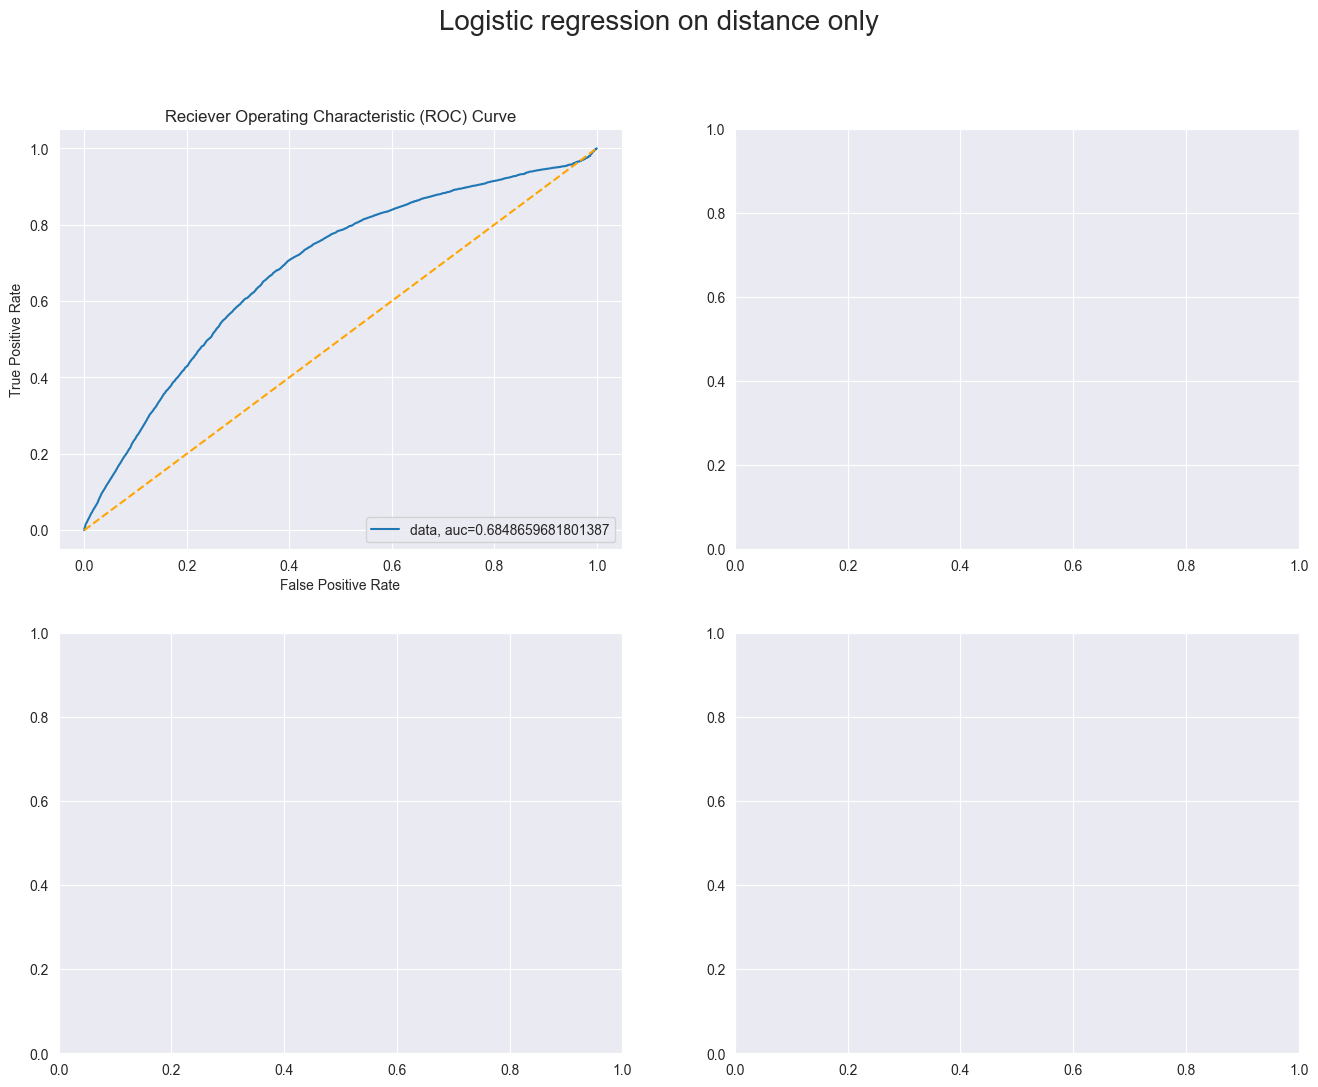

In [14]:
sns.set_style("darkgrid")
fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(16,12))
y_dist_pred_proba = model_dist.predict_proba(X_dist_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_dist_test,  y_dist_pred_proba)
auc = metrics.roc_auc_score(y_dist_test, y_dist_pred_proba)
axes[0,0].plot(fpr,tpr,label="data, auc="+str(auc))
axes[0,0].plot([0,1],[0,1],color='orange',linestyle='--')
axes[0,0].set_xlabel('False Positive Rate')
axes[0,0].set_ylabel('True Positive Rate')
axes[0,0].set_title('Reciever Operating Characteristic (ROC) Curve')
axes[0,0].legend(loc=4)
fig.suptitle("Logistic regression on distance only", fontsize = 20)

In [18]:
Dict_proba = {'Goal_Proba': model_dist.predict_proba(X_dist_test)[:,1]}
Dict_proba
df_proba = pd.DataFrame(Dict_proba)
df_proba

df_proba['Percentiles'] = df_proba.apply(lambda x: percentileofscore(df_proba['Goal_Proba'],x))
df_proba

df_proba['Goals'] = y_dist_test
df_proba_sorted = df_proba.sort_values(by='Percentiles', ascending = False)
df_proba_sorted

df_proba_sorted['Goals_Cum'] = df_proba_sorted['Goals'].cumsum()
df_proba_sorted

df_proba_sorted.reset_index(drop = True, inplace=True)
df_proba_sorted['Event_count_cum'] = df_proba_sorted.index+1
df_proba_sorted


df_proba_sorted = df_proba_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

df_proba_sorted['Goals_Cum_Portion'] = df_proba_sorted['Goals_Cum']/max(df_proba_sorted['Goals_Cum'])
df_proba_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum,Goals_rate,Goals_Cum_Portion
0,0.171826,99.999196,1,1,1,1.000000,0.00017
1,0.171826,99.999196,0,1,2,0.500000,0.00017
2,0.169967,99.995178,1,2,3,0.666667,0.00034
3,0.169967,99.995178,1,3,4,0.750000,0.00051
4,0.169967,99.995178,0,3,5,0.600000,0.00051
...,...,...,...,...,...,...,...
62212,0.003260,0.008036,1,5876,62213,0.094450,0.99983
62213,0.003258,0.006429,1,5877,62214,0.094464,1.00000
62214,0.003213,0.004822,0,5877,62215,0.094463,1.00000
62215,0.003162,0.003215,0,5877,62216,0.094461,1.00000


In [19]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_rate', ax=axes[0,1])
axes[0,1].set_title("Goal rate")

Text(0.5, 1.0, 'Goal rate')

In [20]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_Cum_Portion', ax=axes[1,0])
axes[1,0].set_title("Cumulative % of goals")

Text(0.5, 1.0, 'Cumulative % of goals')

Text(0.5, 1.0, 'Calibration curve')

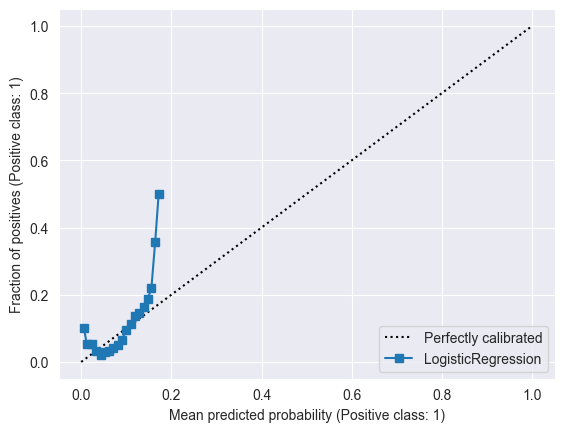

In [21]:
disp_test = CalibrationDisplay.from_estimator(model_dist,X_dist_test, y_dist_test, n_bins = 105)
disp_test.plot(ax=axes[1,1])
axes[1,1].set_title("Calibration curve")

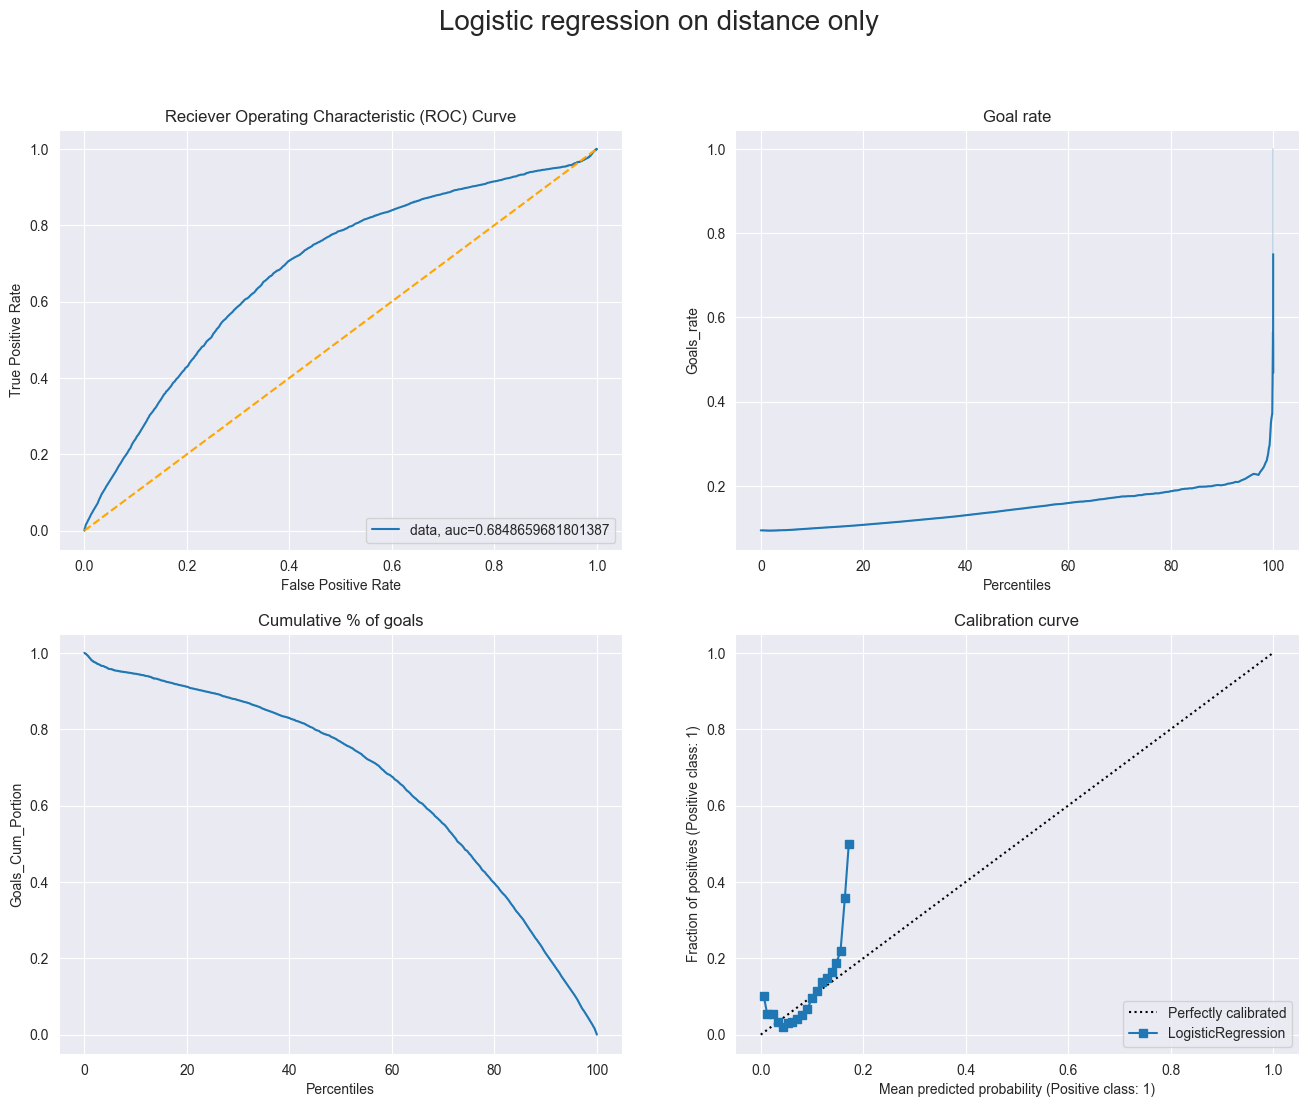

In [22]:
fig

## Model on angle only

In [23]:
X_angle = my_data[:,35]
X_angle = X_angle.reshape(-1,1)
y_angle = my_data[:, 39]
y_angle = y_angle.astype('int')
X_angle_train, X_angle_test, y_angle_train, y_angle_test = train_test_split(X_angle, y_angle, test_size = 0.20, random_state=42)
lr_angle = LogisticRegression()
model_angle = lr_angle.fit(X_angle_train,y_angle_train)
print('Accuracy on training data: ', round(model_angle.score(X_angle_train,y_angle_train),2))
result_angle = model_angle.score(X_angle_test,y_angle_test)
print('Accuracy on testing data: ', round(result_angle*100,2))

Accuracy on training data:  0.91
Accuracy on testing data:  90.55


Text(0.5, 0.98, 'Logistic regression on angle only')

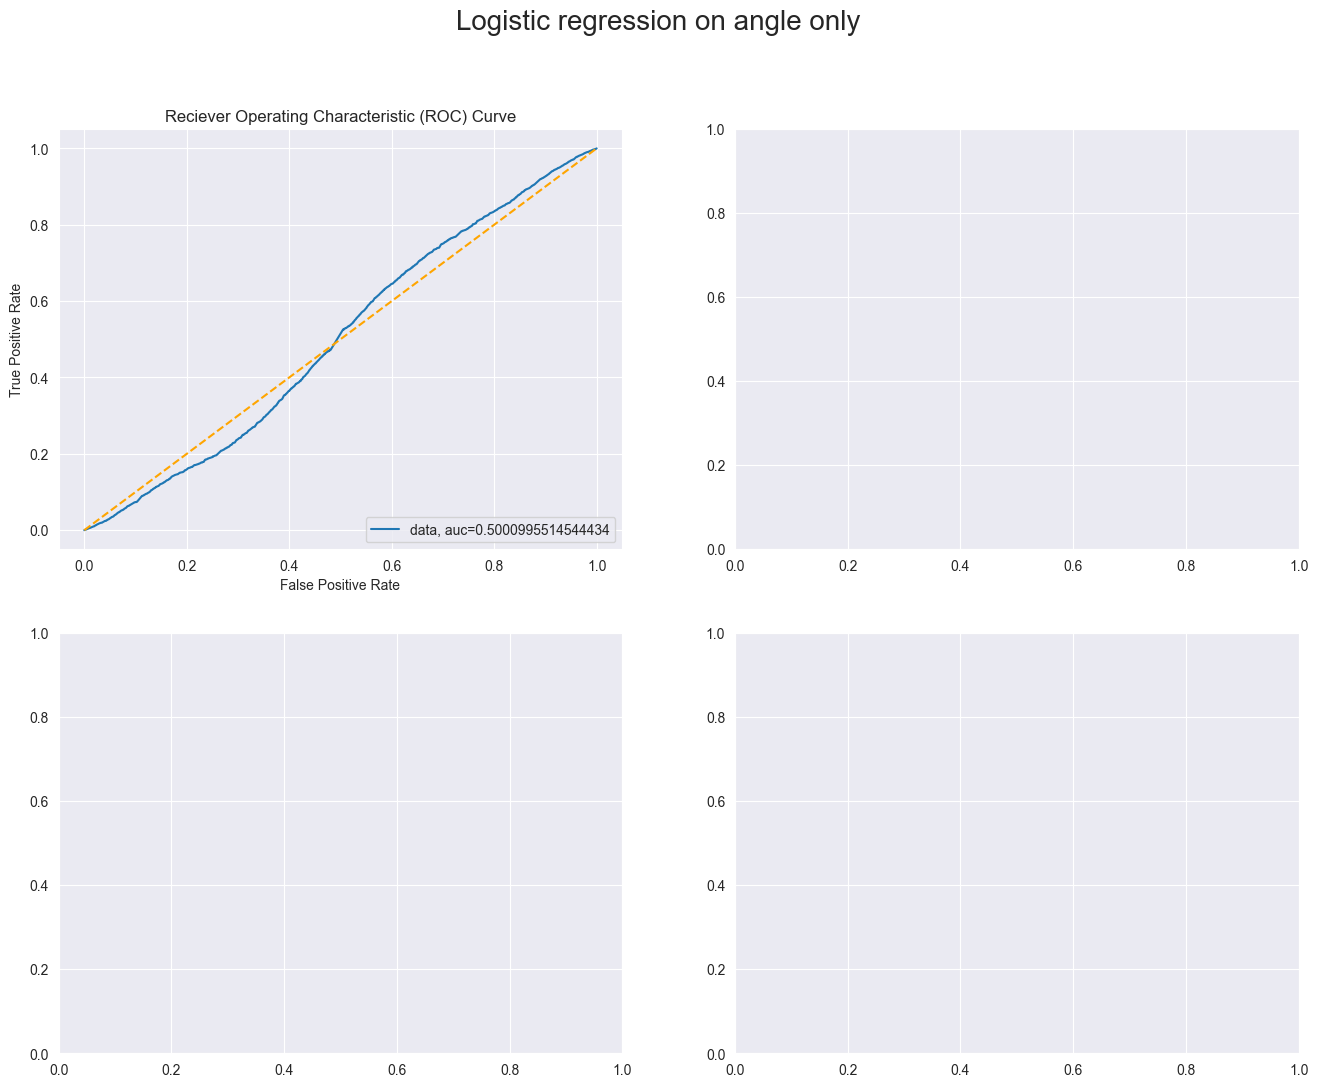

In [24]:
fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(16,12))
y_angle_pred_proba = model_angle.predict_proba(X_angle_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_angle_test,  y_angle_pred_proba)
auc = metrics.roc_auc_score(y_angle_test, y_angle_pred_proba)
axes[0,0].plot(fpr,tpr,label="data, auc="+str(auc))
axes[0,0].plot([0,1],[0,1],color='orange',linestyle='--')
axes[0,0].set_xlabel('False Positive Rate')
axes[0,0].set_ylabel('True Positive Rate')
axes[0,0].set_title('Reciever Operating Characteristic (ROC) Curve')
axes[0,0].legend(loc=4)
fig.suptitle("Logistic regression on angle only", fontsize = 20)


In [25]:
Dict_proba_angle = {'Goal_Proba': model_angle.predict_proba(X_angle_test)[:,1]}
Dict_proba_angle
df_proba_angle = pd.DataFrame(Dict_proba_angle)
df_proba_angle

df_proba_angle['Percentiles'] = df_proba_angle.apply(lambda x: percentileofscore(df_proba_angle['Goal_Proba'],x))
df_proba_angle

df_proba_angle['Goals'] = y_angle_test
df_proba_angle_sorted = df_proba_angle.sort_values(by='Percentiles', ascending = False)
df_proba_angle_sorted

df_proba_angle_sorted['Goals_Cum'] = df_proba_angle_sorted['Goals'].cumsum()
df_proba_angle_sorted

df_proba_angle_sorted.reset_index(drop = True, inplace=True)
df_proba_angle_sorted['Event_count_cum'] = df_proba_angle_sorted.index+1
df_proba_angle_sorted


df_proba_angle_sorted = df_proba_angle_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

df_proba_angle_sorted['Goals_Cum_Portion'] = df_proba_angle_sorted['Goals_Cum']/max(df_proba_angle_sorted['Goals_Cum'])
df_proba_angle_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum,Goals_rate,Goals_Cum_Portion
0,0.098109,99.961425,0,0,1,0.000000,0.00000
1,0.098109,99.961425,0,0,2,0.000000,0.00000
2,0.098109,99.961425,0,0,3,0.000000,0.00000
3,0.098109,99.961425,0,0,4,0.000000,0.00000
4,0.098109,99.961425,1,1,5,0.200000,0.00017
...,...,...,...,...,...,...,...
62212,0.089352,0.049826,0,5876,62213,0.094450,0.99983
62213,0.089352,0.049826,0,5876,62214,0.094448,0.99983
62214,0.089352,0.049826,0,5876,62215,0.094447,0.99983
62215,0.089352,0.049826,0,5876,62216,0.094445,0.99983


In [26]:
sns.lineplot(df_proba_angle_sorted, x='Percentiles', y= 'Goals_rate', ax=axes[0,1])
axes[0,1].set_title("Goal rate")

Text(0.5, 1.0, 'Goal rate')

In [27]:
sns.lineplot(df_proba_angle_sorted, x='Percentiles', y= 'Goals_Cum_Portion', ax=axes[1,0])
axes[1,0].set_title("Cumulative % of goals")

Text(0.5, 1.0, 'Cumulative % of goals')

Text(0.5, 1.0, 'Calibration curve')

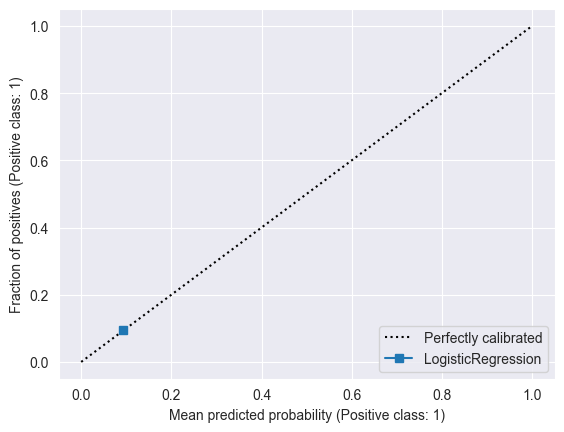

In [28]:
disp_angle_test = CalibrationDisplay.from_estimator(model_angle,X_angle_test, y_angle_test, n_bins = 10)
disp_angle_test.plot(ax=axes[1,1])
axes[1,1].set_title("Calibration curve")

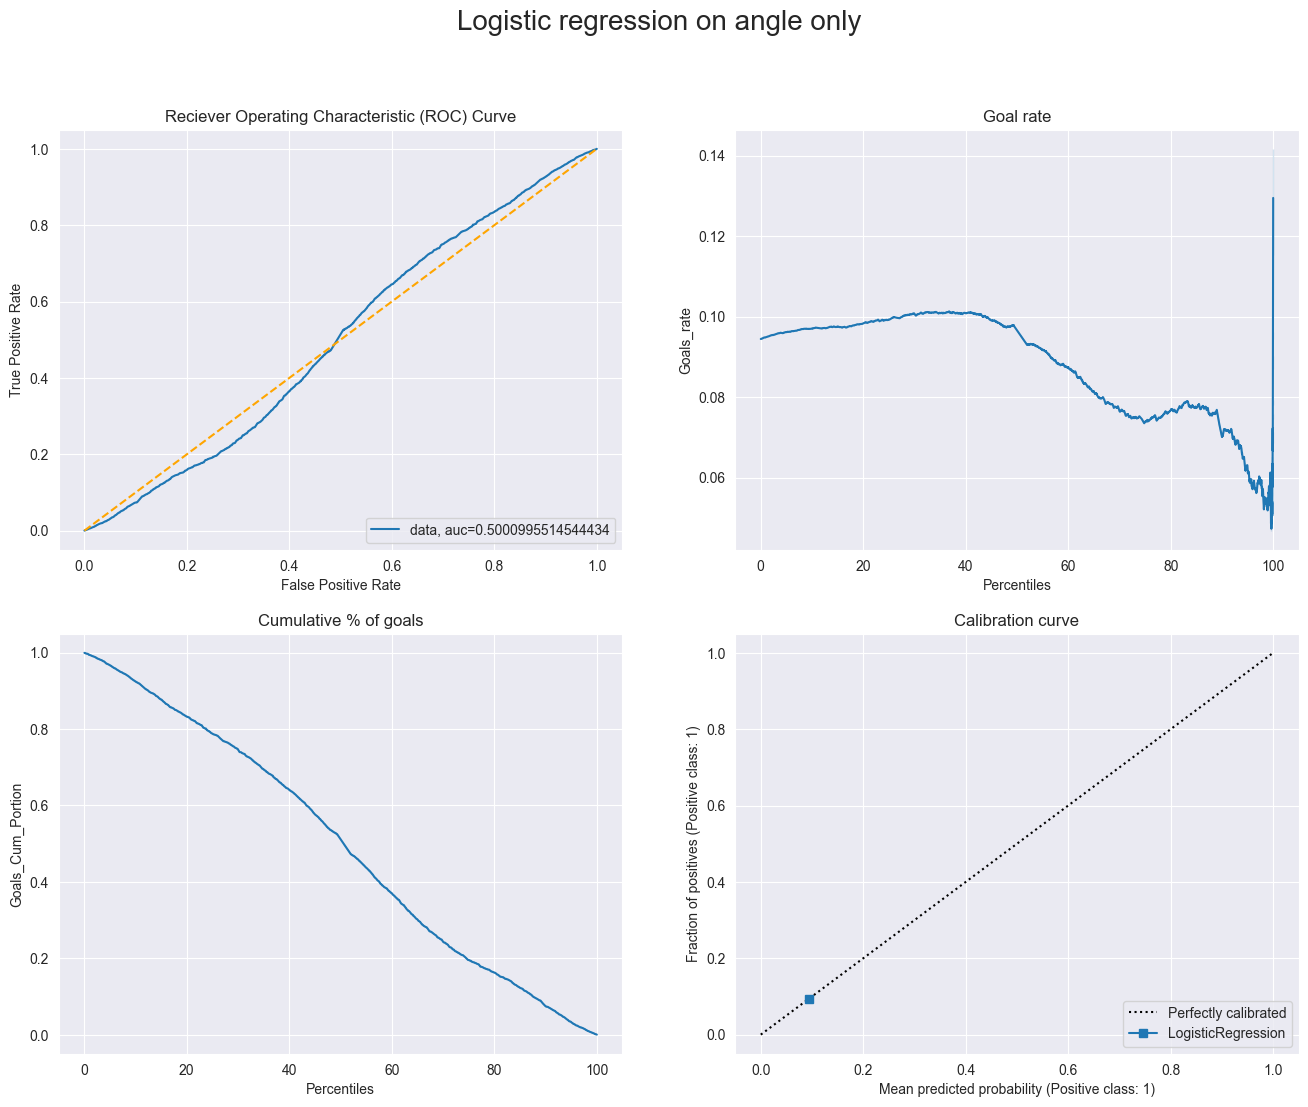

In [29]:
fig

## Model on distance and angle

In [30]:
X = my_data[:,33], my_data[:,35]
X = np.asarray(X).transpose()
y = my_data[:, 39]
y = y.astype('int')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state=42)
lr = LogisticRegression()
model = lr.fit(X_train,y_train)
print('Accuracy on training data: ', round(model.score(X_train,y_train),2))
result = model.score(X_test,y_test)
print('Accuracy on testing data: ', round(result*100,2))

Accuracy on training data:  0.91
Accuracy on testing data:  90.55


Text(0.5, 0.98, 'Logistic regression on distance and angle')

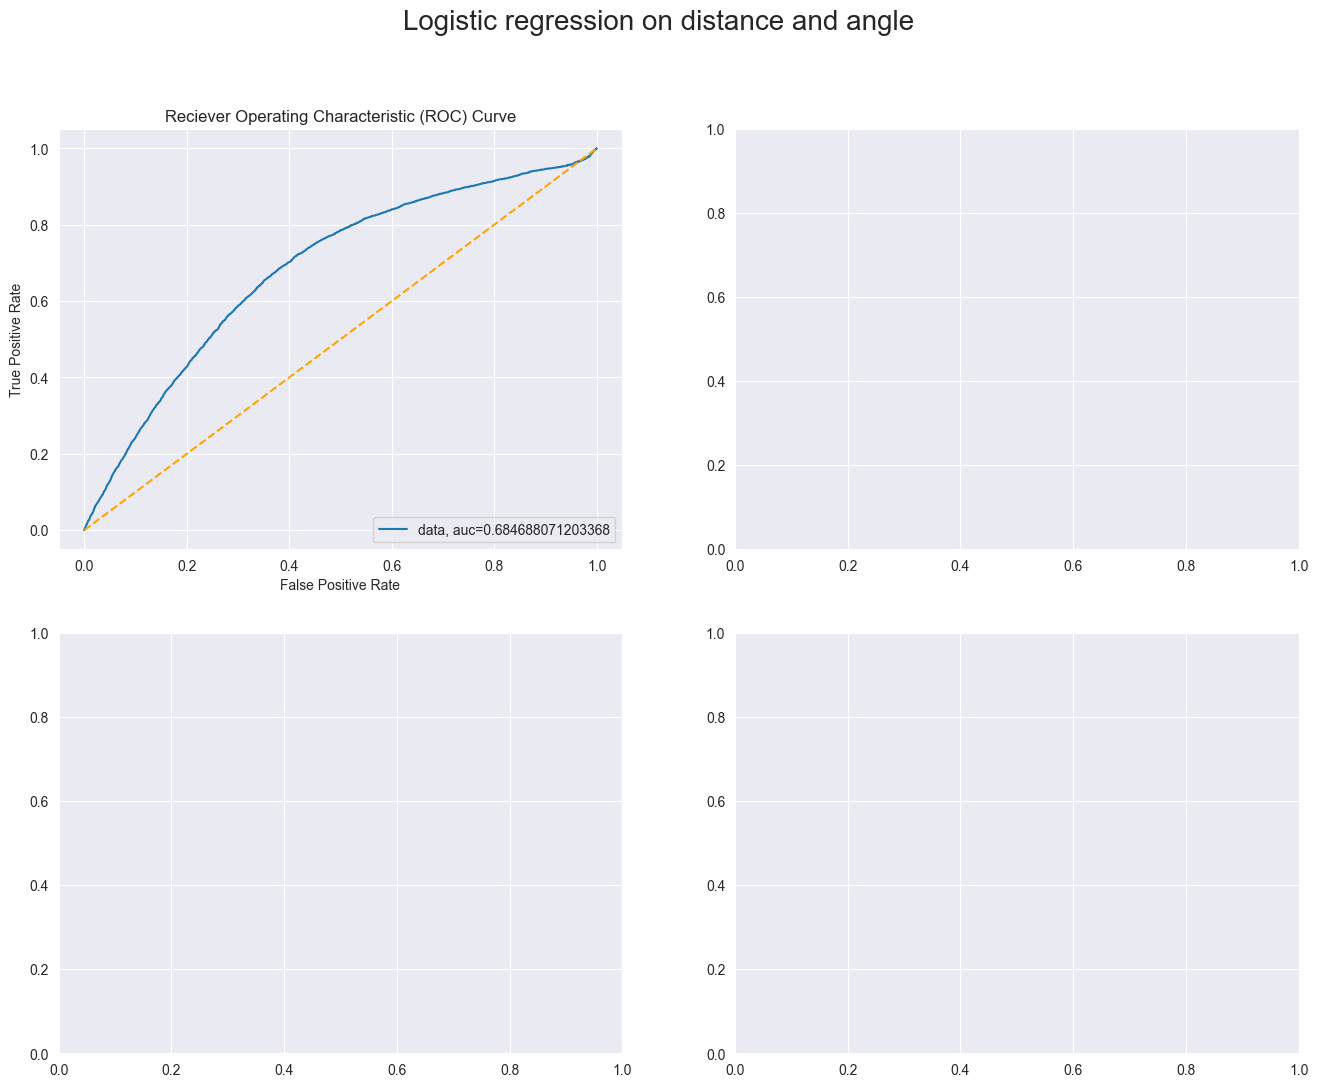

In [31]:
fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(16,12))
y_pred_proba = model.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
axes[0,0].plot(fpr,tpr,label="data, auc="+str(auc))
axes[0,0].plot([0,1],[0,1],color='orange',linestyle='--')
axes[0,0].set_xlabel('False Positive Rate')
axes[0,0].set_ylabel('True Positive Rate')
axes[0,0].set_title('Reciever Operating Characteristic (ROC) Curve')
axes[0,0].legend(loc=4)
fig.suptitle("Logistic regression on distance and angle", fontsize = 20)

In [32]:
Dict_proba_both = {'Goal_Proba': model.predict_proba(X_test)[:,1]}
Dict_proba_both
df_proba_both = pd.DataFrame(Dict_proba_both)
df_proba_both

df_proba_both['Percentiles'] = df_proba_both.apply(lambda x: percentileofscore(df_proba_both['Goal_Proba'],x))
df_proba_both

df_proba_both['Goals'] = y_test
df_proba_both_sorted = df_proba_both.sort_values(by='Percentiles', ascending = False)
df_proba_both_sorted

df_proba_both_sorted['Goals_Cum'] = df_proba_both_sorted['Goals'].cumsum()
df_proba_both_sorted

df_proba_both_sorted.reset_index(drop = True, inplace=True)
df_proba_both_sorted['Event_count_cum'] = df_proba_both_sorted.index+1
df_proba_both_sorted


df_proba_both_sorted = df_proba_both_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

df_proba_both_sorted['Goals_Cum_Portion'] = df_proba_both_sorted['Goals_Cum']/max(df_proba_both_sorted['Goals_Cum'])
df_proba_both_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum,Goals_rate,Goals_Cum_Portion
0,0.175131,100.000000,0,0,1,0.000000,0.00000
1,0.172900,99.994375,1,1,2,0.500000,0.00017
2,0.172900,99.994375,1,2,3,0.666667,0.00034
3,0.172900,99.994375,0,2,4,0.500000,0.00034
4,0.172900,99.994375,1,3,5,0.600000,0.00051
...,...,...,...,...,...,...,...
62212,0.003240,0.008036,1,5876,62213,0.094450,0.99983
62213,0.003231,0.006429,1,5877,62214,0.094464,1.00000
62214,0.003217,0.004822,0,5877,62215,0.094463,1.00000
62215,0.003156,0.003215,0,5877,62216,0.094461,1.00000


In [33]:
sns.lineplot(df_proba_both_sorted, x='Percentiles', y= 'Goals_rate', ax=axes[0,1])
axes[0,1].set_title("Goal rate")

Text(0.5, 1.0, 'Goal rate')

In [34]:
sns.lineplot(df_proba_both_sorted, x='Percentiles', y= 'Goals_Cum_Portion', ax=axes[1,0])
axes[1,0].set_title("Cumulative % of goals")

Text(0.5, 1.0, 'Cumulative % of goals')

Text(0.5, 1.0, 'Calibration curve')

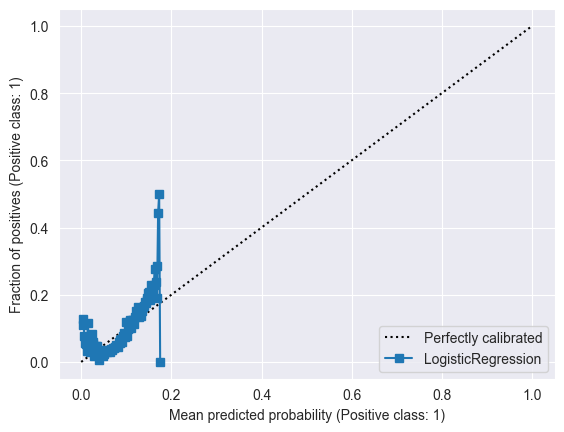

In [35]:
disp_both_test = CalibrationDisplay.from_estimator(model,X_test, y_test, n_bins = 500)
disp_both_test.plot(ax=axes[1,1])
axes[1,1].set_title("Calibration curve")

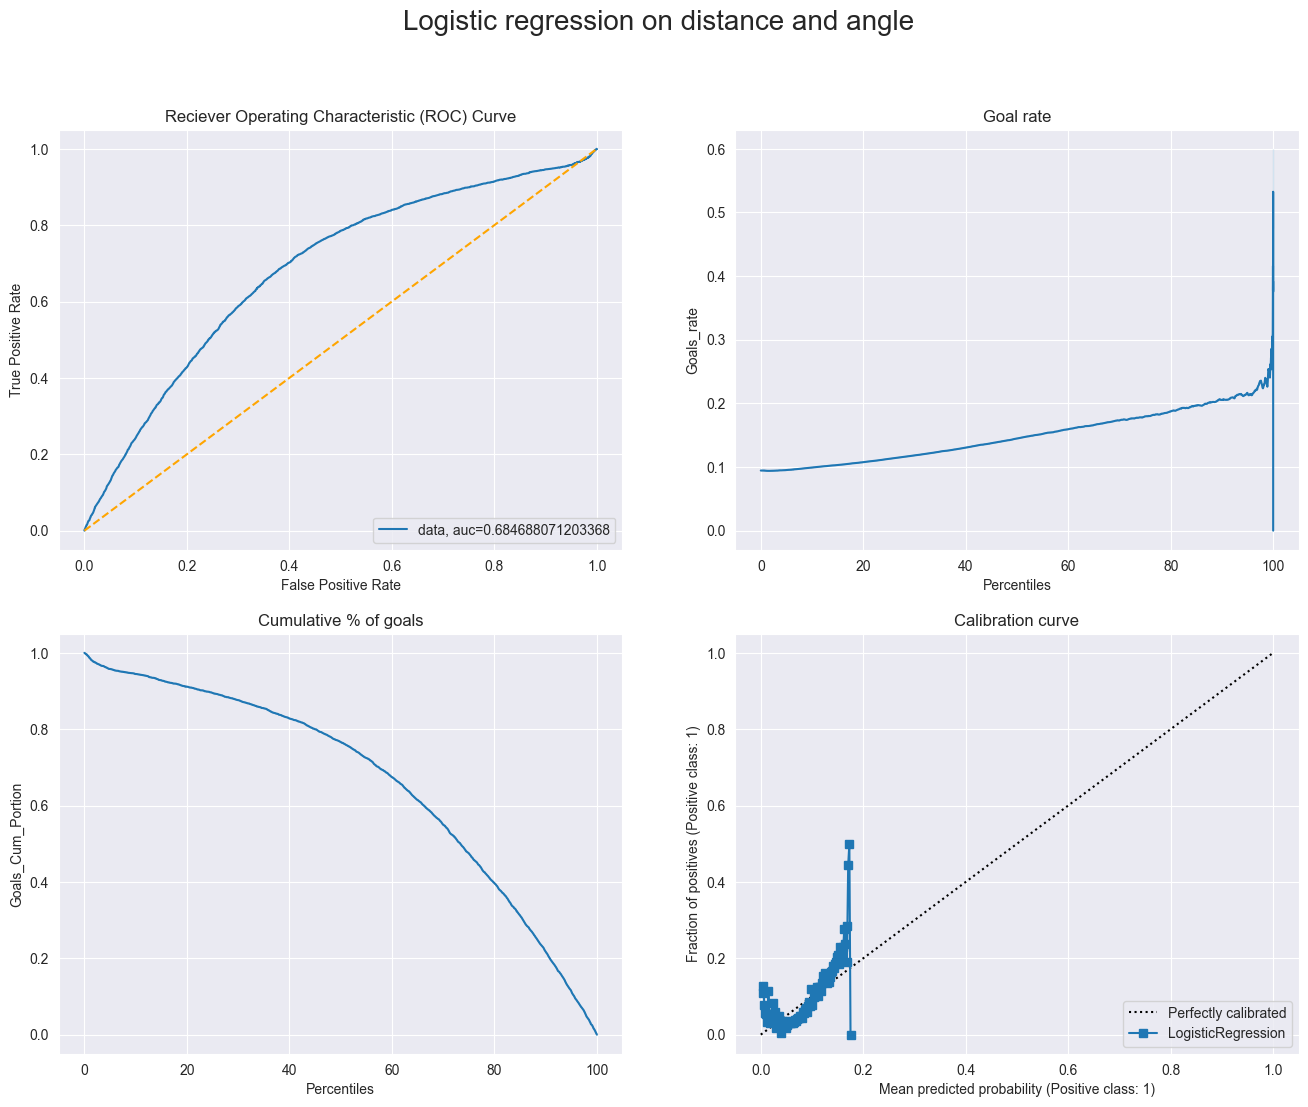

In [37]:
fig

## Random Baseline

In [38]:
y = my_data[:, 39]
y = y.astype('int')
y_train, y_test = train_test_split(y, test_size = 0.20, random_state=42)
predict_proba_train = np.random.uniform(0,1,len(y_train))
predict_proba_test = np.random.uniform(0,1,len(y_test))
acc_train = metrics.accuracy_score(y_train, predict_proba_train>=0.5)
print('Accuracy on training data: ', acc_train)
acc_test = metrics.accuracy_score(y_test, predict_proba_test>=0.5)
print('Accuracy on testing data: ', acc_test)

Accuracy on training data:  0.500912130125207
Accuracy on testing data:  0.4960862786698169


Text(0.5, 0.98, 'Random uniform prediction probabilities')

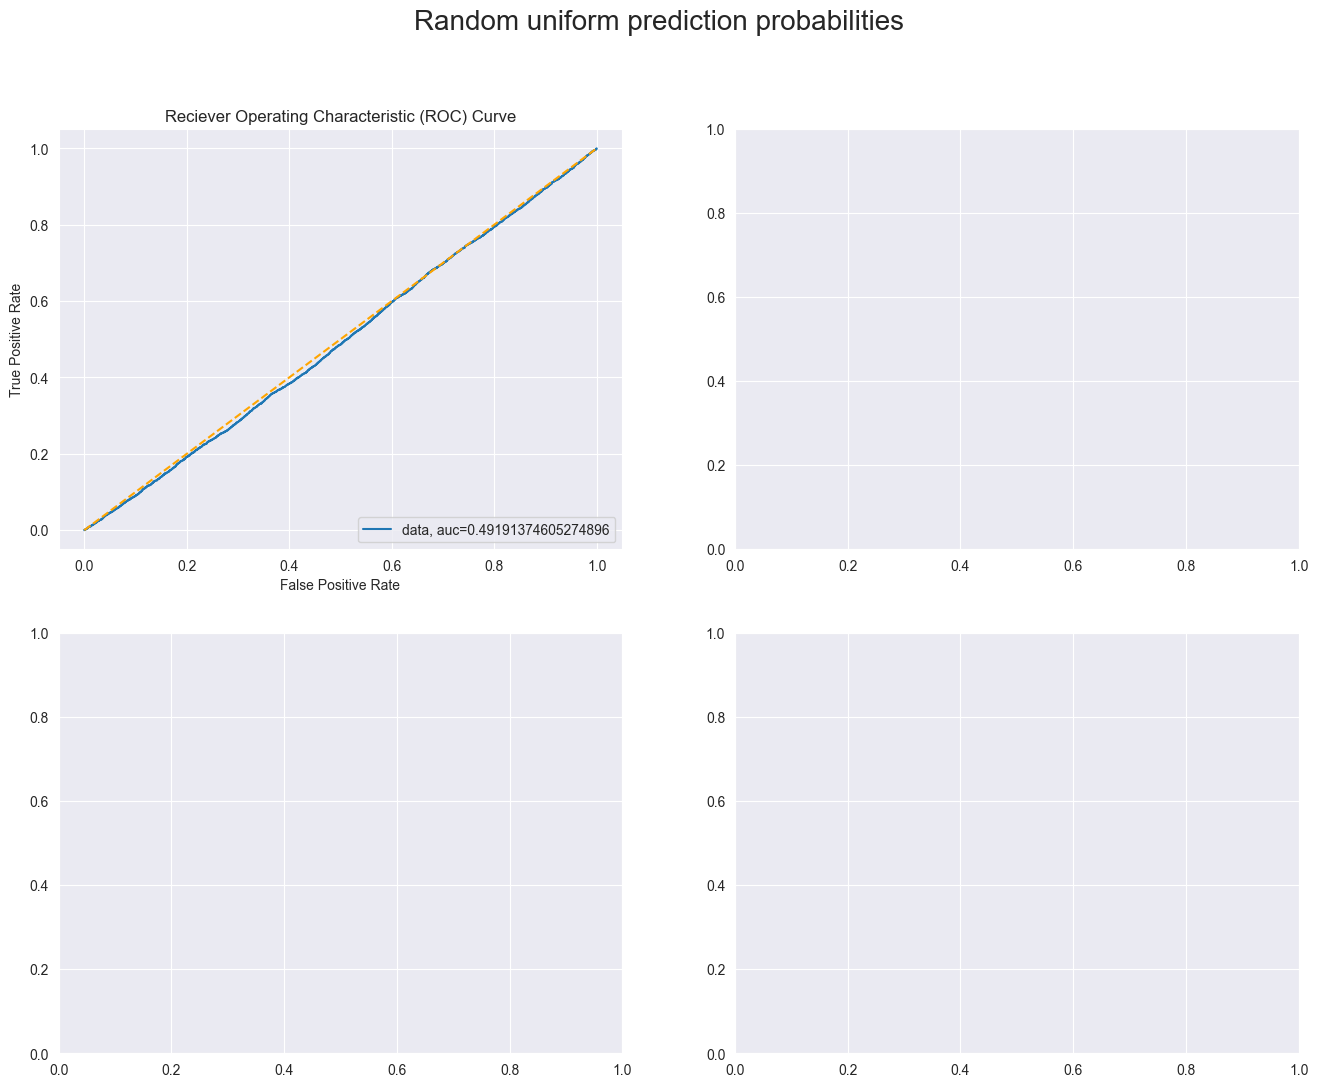

In [39]:
fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(16,12))
fpr, tpr, _ = metrics.roc_curve(y_test,  predict_proba_test)
auc = metrics.roc_auc_score(y_test, predict_proba_test)
axes[0,0].plot(fpr,tpr,label="data, auc="+str(auc))
axes[0,0].plot([0,1],[0,1],color='orange',linestyle='--')
axes[0,0].set_xlabel('False Positive Rate')
axes[0,0].set_ylabel('True Positive Rate')
axes[0,0].set_title('Reciever Operating Characteristic (ROC) Curve')
axes[0,0].legend(loc=4)
fig.suptitle("Random uniform prediction probabilities", fontsize = 20)

In [40]:
Dict_proba_both = {'Goal_Proba':predict_proba_test}
Dict_proba_both
df_proba_both = pd.DataFrame(Dict_proba_both)
df_proba_both

df_proba_both['Percentiles'] = df_proba_both.apply(lambda x: percentileofscore(df_proba_both['Goal_Proba'],x))
df_proba_both

df_proba_both['Goals'] = y_test
df_proba_both_sorted = df_proba_both.sort_values(by='Percentiles', ascending = False)
df_proba_both_sorted

df_proba_both_sorted['Goals_Cum'] = df_proba_both_sorted['Goals'].cumsum()
df_proba_both_sorted

df_proba_both_sorted.reset_index(drop = True, inplace=True)
df_proba_both_sorted['Event_count_cum'] = df_proba_both_sorted.index+1
df_proba_both_sorted


df_proba_both_sorted = df_proba_both_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

df_proba_both_sorted['Goals_Cum_Portion'] = df_proba_both_sorted['Goals_Cum']/max(df_proba_both_sorted['Goals_Cum'])
df_proba_both_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum,Goals_rate,Goals_Cum_Portion
0,0.999988,100.000000,1,1,1,1.000000,0.00017
1,0.999986,99.998393,1,2,2,1.000000,0.00034
2,0.999966,99.996785,0,2,3,0.666667,0.00034
3,0.999966,99.995178,0,2,4,0.500000,0.00034
4,0.999959,99.993571,0,2,5,0.400000,0.00034
...,...,...,...,...,...,...,...
62212,0.000166,0.008036,0,5877,62213,0.094466,1.00000
62213,0.000166,0.006429,0,5877,62214,0.094464,1.00000
62214,0.000117,0.004822,0,5877,62215,0.094463,1.00000
62215,0.000114,0.003215,0,5877,62216,0.094461,1.00000


In [41]:
sns.lineplot(df_proba_both_sorted, x='Percentiles', y= 'Goals_rate', ax=axes[0,1])
axes[0,1].set_title("Goal rate")

Text(0.5, 1.0, 'Goal rate')

In [42]:
sns.lineplot(df_proba_both_sorted, x='Percentiles', y= 'Goals_Cum_Portion', ax=axes[1,0])
axes[1,0].set_title("Cumulative % of goals")

Text(0.5, 1.0, 'Cumulative % of goals')

Text(0.5, 1.0, 'Calibration curve')

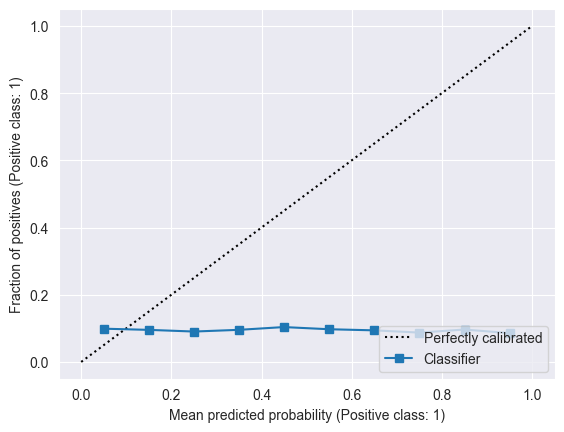

In [43]:
disp_both_test = CalibrationDisplay.from_predictions(y_test, predict_proba_test, n_bins = 10)
disp_both_test.plot(ax=axes[1,1])
axes[1,1].set_title("Calibration curve")

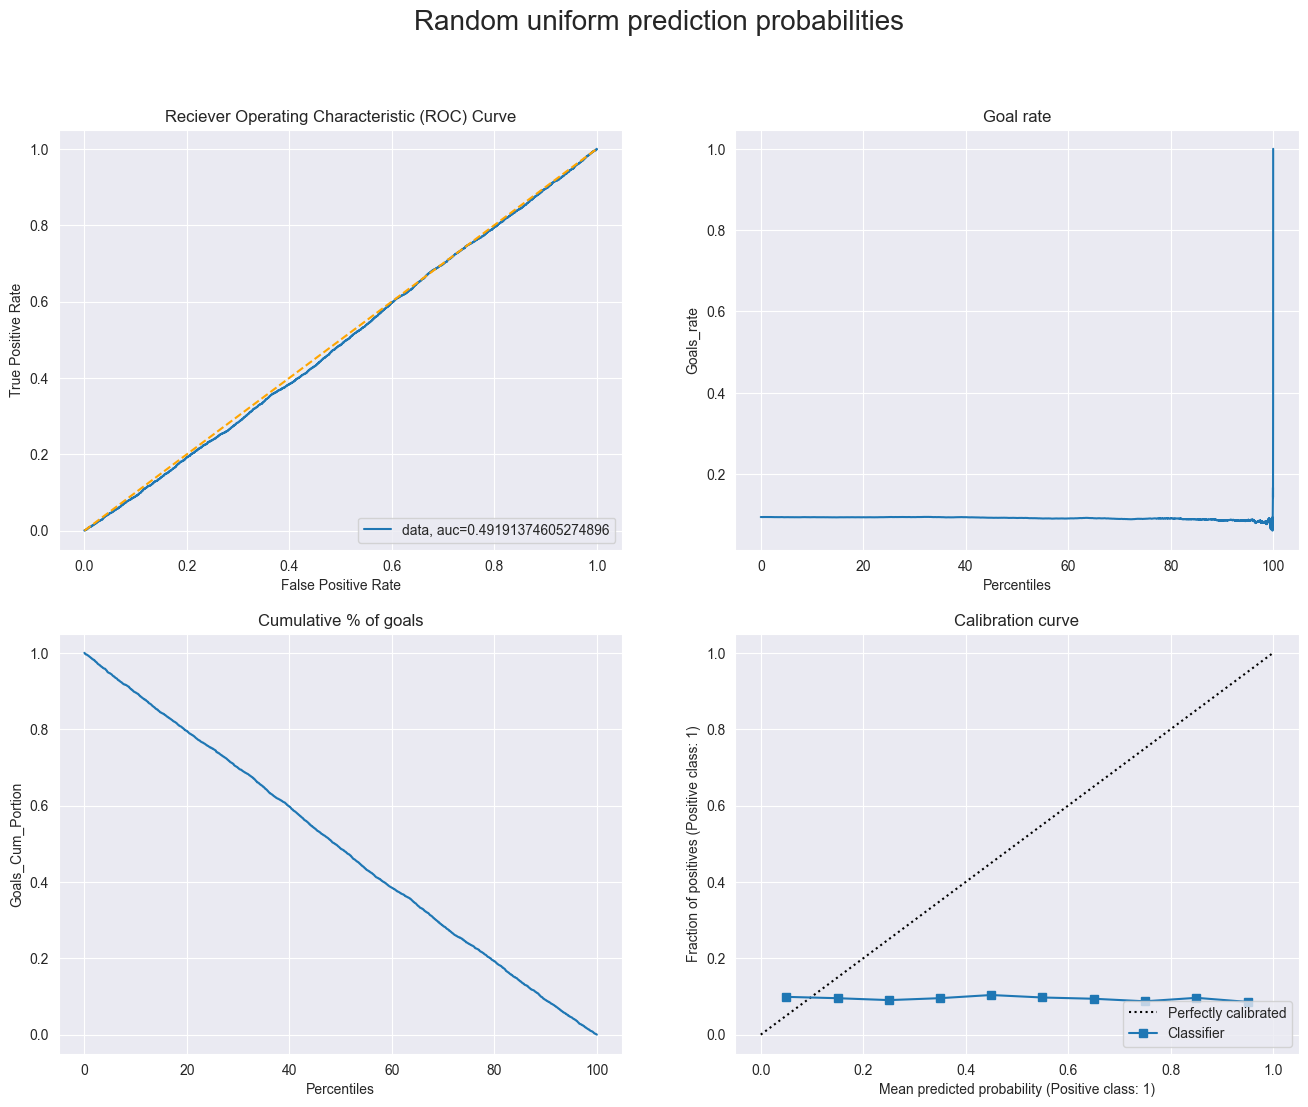

In [44]:
fig

## Predict proba (SKIP)

In [ ]:
max(model_dist.predict_proba(X_dist_test)[:,1])

In [ ]:
max(model_angle.predict_proba(X_dist_test)[:,1])

In [ ]:
max(model.predict_proba(X_test)[:,1])

In [ ]:
df_model

In [ ]:
df_model[df_model['Event_Type_Binary']==1]['Event_Type_Binary'].count()/df_model['Event_Type_Binary'].count()

In [ ]:
df_model['Event_Type_Binary'].count()

In [ ]:
X_test

In [ ]:
#np.random.uniform(14000,0,1)
## Percentiles

In [ ]:
Dict_proba = {'Goal_Proba': model_dist.predict_proba(X_dist_test)[:,1]}
Dict_proba
df_proba = pd.DataFrame(Dict_proba)
df_proba
from scipy.stats import percentileofscore
df_proba['Percentiles'] = df_proba.apply(lambda x: percentileofscore(df_proba['Goal_Proba'],x))
df_proba

In [ ]:
y_dist_test

In [ ]:
df_proba['Goals'] = y_dist_test
df_proba_sorted = df_proba.sort_values(by='Percentiles', ascending = False)
df_proba_sorted

In [ ]:
df_proba_sorted['Goals_Cum'] = df_proba_sorted['Goals'].cumsum()
df_proba_sorted

In [ ]:
df_proba_sorted.reset_index(drop = True, inplace=True)

In [ ]:
df_proba_sorted['Event_count_cum'] = df_proba_sorted.index+1
df_proba_sorted

In [ ]:
df_proba_sorted = df_proba_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

In [ ]:
df_proba_sorted['Goals_Cum_Portion'] = df_proba_sorted['Goals_Cum']/max(df_proba_sorted['Goals_Cum'])
df_proba_sorted

In [ ]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_rate')

In [ ]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_Cum_Portion')

In [ ]:
from sklearn.calibration import calibration_curve, CalibrationDisplay
y_dist_prob = model_dist.predict_proba(X_dist_test)[:,1]
prob_dist_true, prob_dist_pred = calibration_curve(y_dist_test, y_dist_prob, n_bins = 50)
disp_dist = CalibrationDisplay(prob_dist_true, prob_dist_pred, y_dist_prob)
disp_dist.plot()

In [ ]:
disp_test = CalibrationDisplay.from_estimator(model_dist,X_dist_test, y_dist_test, n_bins = 105)
plt.show()

In [131]:
df_model[df_model['Event_Type_Binary']==1]['Event_Type_Binary'].count()/df_model['Event_Type_Binary'].count()

0.09378465692656347

In [132]:
df_model['Event_Type_Binary'].count()

311085

In [133]:
X_test

array([[49.51767361255979, 43.36342295838328],
       [29.410882339705484, -35.31121343963321],
       [50.20956084253277, 44.19307054489763],
       ...,
       [15.297058540778355, 78.69006752597979],
       [60.41522986797286, -24.443954780416536],
       [89.98888820293314, -14.808377039042396]], dtype=object)

In [ ]:
#np.random.uniform(14000,0,1)
## Percentiles

In [18]:
Dict_proba = {'Goal_Proba': model_dist.predict_proba(X_dist_test)[:,1]}
Dict_proba
df_proba = pd.DataFrame(Dict_proba)
df_proba
from scipy.stats import percentileofscore
df_proba['Percentiles'] = df_proba.apply(lambda x: percentileofscore(df_proba['Goal_Proba'],x))
df_proba

,Goal_Proba,Percentiles
0,0.066063,26.459006
1,0.100070,57.368565
2,0.065109,25.506694
3,0.154656,97.113329
4,0.073693,33.598534
...,...,...
62212,0.107031,62.397737
62213,0.025674,4.355723
62214,0.132514,78.477747
62215,0.052452,11.189868


In [60]:
y_dist_test

array([0, 0, 0, ..., 0, 0, 0])

In [61]:
df_proba['Goals'] = y_dist_test
df_proba_sorted = df_proba.sort_values(by='Percentiles', ascending = False)
df_proba_sorted

,Goal_Proba,Percentiles,Goals
39426,0.174041,100.000000,1
41184,0.172706,99.998393,1
22071,0.170831,99.995178,0
28598,0.170831,99.995178,1
47884,0.170831,99.995178,0
...,...,...,...
20503,0.003203,0.007233,0
19788,0.003203,0.007233,1
41692,0.003193,0.004822,0
32053,0.003169,0.003215,0


In [62]:
df_proba_sorted['Goals_Cum'] = df_proba_sorted['Goals'].cumsum()
df_proba_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum
39426,0.174041,100.000000,1,1
41184,0.172706,99.998393,1,2
22071,0.170831,99.995178,0,2
28598,0.170831,99.995178,1,3
47884,0.170831,99.995178,0,3
...,...,...,...,...
20503,0.003203,0.007233,0,5795
19788,0.003203,0.007233,1,5796
41692,0.003193,0.004822,0,5796
32053,0.003169,0.003215,0,5796


In [63]:
df_proba_sorted.reset_index(drop = True, inplace=True)

In [64]:
df_proba_sorted['Event_count_cum'] = df_proba_sorted.index+1
df_proba_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum
0,0.174041,100.000000,1,1,1
1,0.172706,99.998393,1,2,2
2,0.170831,99.995178,0,2,3
3,0.170831,99.995178,1,3,4
4,0.170831,99.995178,0,3,5
...,...,...,...,...,...
62212,0.003203,0.007233,0,5795,62213
62213,0.003203,0.007233,1,5796,62214
62214,0.003193,0.004822,0,5796,62215
62215,0.003169,0.003215,0,5796,62216


In [65]:
df_proba_sorted = df_proba_sorted.assign(Goals_rate = lambda x: x['Goals_Cum']/x['Event_count_cum'])

In [66]:
df_proba_sorted['Goals_Cum_Portion'] = df_proba_sorted['Goals_Cum']/max(df_proba_sorted['Goals_Cum'])
df_proba_sorted

,Goal_Proba,Percentiles,Goals,Goals_Cum,Event_count_cum,Goals_rate,Goals_Cum_Portion
0,0.174041,100.000000,1,1,1,1.000000,0.000173
1,0.172706,99.998393,1,2,2,1.000000,0.000345
2,0.170831,99.995178,0,2,3,0.666667,0.000345
3,0.170831,99.995178,1,3,4,0.750000,0.000518
4,0.170831,99.995178,0,3,5,0.600000,0.000518
...,...,...,...,...,...,...,...
62212,0.003203,0.007233,0,5795,62213,0.093148,0.999827
62213,0.003203,0.007233,1,5796,62214,0.093162,1.000000
62214,0.003193,0.004822,0,5796,62215,0.093161,1.000000
62215,0.003169,0.003215,0,5796,62216,0.093159,1.000000


<AxesSubplot: xlabel='Percentiles', ylabel='Goals_rate'>

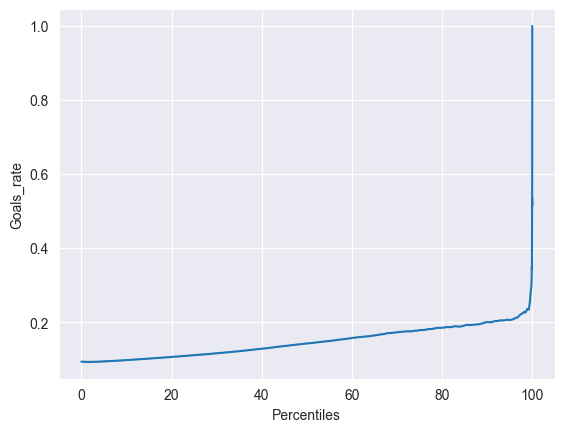

In [67]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_rate')

<AxesSubplot: xlabel='Percentiles', ylabel='Goals_Cum_Portion'>

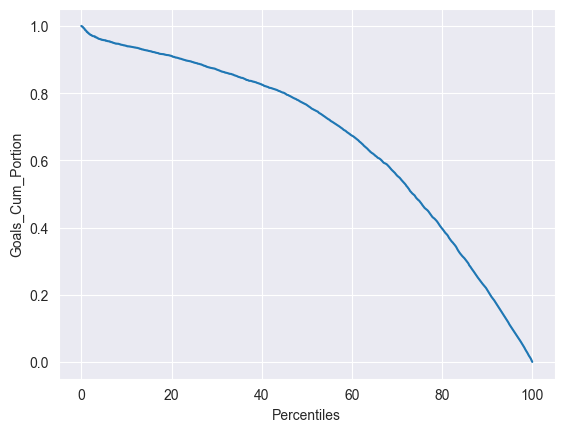

In [68]:
sns.lineplot(df_proba_sorted, x='Percentiles', y= 'Goals_Cum_Portion')

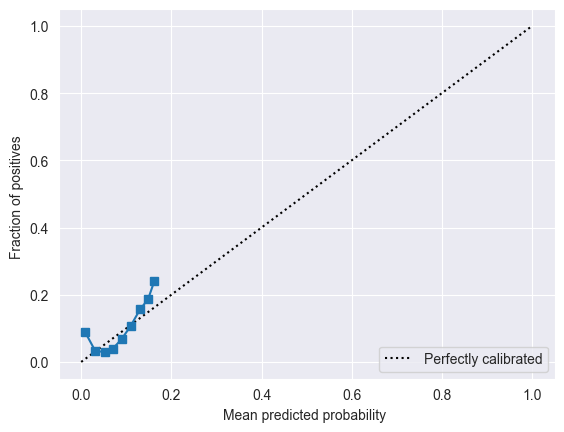

In [94]:
from sklearn.calibration import calibration_curve, CalibrationDisplay
y_dist_prob = model_dist.predict_proba(X_dist_test)[:,1]
prob_dist_true, prob_dist_pred = calibration_curve(y_dist_test, y_dist_prob, n_bins = 50)
disp_dist = CalibrationDisplay(prob_dist_true, prob_dist_pred, y_dist_prob)
disp_dist.plot()

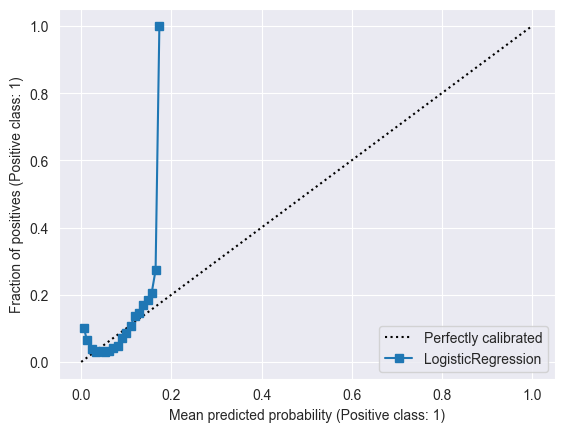

In [108]:
disp_test = CalibrationDisplay.from_estimator(model_dist,X_dist_test, y_dist_test, n_bins = 105)
plt.show()